<a href="https://colab.research.google.com/github/ck3378/GPU-Accelerated-Deep-Learning-Engine/blob/main/Matrix_Mul_CPU_GPU_Custom_Cuda_Performance_Benchmarking.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch

# Create CPU matrices
A = torch.tensor([[1, 2], [3, 4]], dtype=torch.float32)
B = torch.tensor([[5, 6], [7, 8]], dtype=torch.float32)

# CPU multiplication
C = torch.matmul(A, B)

# Move matrices to GPU
A_gpu = A.to("cuda")
B_gpu = B.to("cuda")

# GPU multiplication
C_gpu = torch.matmul(A_gpu, B_gpu)

# Compare CPU and GPU results
print("CPU result:")
print(C)

print("\nGPU result:")
print(C_gpu.cpu())

print("\nResults match:", torch.allclose(C, C_gpu.cpu()))

CPU result:
tensor([[19., 22.],
        [43., 50.]])

GPU result:
tensor([[19., 22.],
        [43., 50.]])

Results match: True


In [ ]:
import torch
import time

# Check GPU
device = "cuda"

# Matrix sizes to experiment with
sizes = [256, 512, 1024, 2048]

# Store benchmark results
results = []

for size in sizes:

    # Generate identical input matrices
    A = torch.randn(size, size)
    B = torch.randn(size, size)

    # ---------------- CPU BENCHMARK ----------------

    start = time.perf_counter()

    C_cpu = torch.matmul(A, B)

    cpu_time = time.perf_counter() - start

    # ---------------- GPU BENCHMARK ----------------

    # Transfer matrices to GPU (outside timed section)
    A_gpu = A.to(device)
    B_gpu = B.to(device)

    # Warm-up
    for _ in range(5):
        torch.matmul(A_gpu, B_gpu)

    torch.cuda.synchronize()

    # Measure GPU execution
    start = time.perf_counter()

    for _ in range(20):
        C_gpu = torch.matmul(A_gpu, B_gpu)

    torch.cuda.synchronize()

    gpu_time = (time.perf_counter() - start) / 20

    # Correctness check
    correct = torch.allclose(C_cpu, C_gpu.cpu(), rtol=1e-3, atol=1e-3)

    # Calculate speedup
    speedup = cpu_time / gpu_time

    results.append((size, cpu_time * 1000, gpu_time * 1000, speedup, correct))

# Print results
print("Matrix Size | CPU (ms) | GPU (ms) | Speedup | Correct")

for size, cpu, gpu, speedup, correct in results:
    print(f"{size:6}x{size:<6} | {cpu:8.3f} | {gpu:8.3f} | {speedup:7.2f}x | {correct}")

Matrix Size | CPU (ms) | GPU (ms) | Speedup | Correct
   256x256    |    1.014 |    0.050 |   20.40x | True
   512x512    |    2.184 |    0.133 |   16.38x | True
  1024x1024   |   20.382 |    0.830 |   24.57x | True
  2048x2048   |  143.499 |    6.036 |   23.77x | True


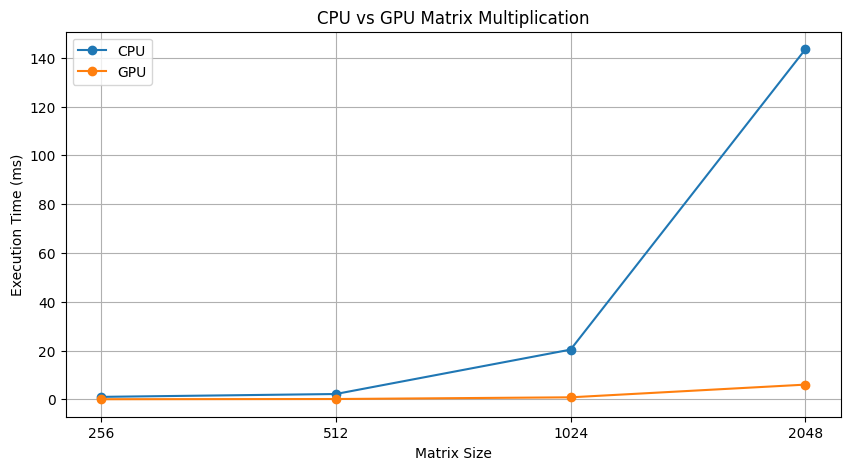

In [ ]:
import matplotlib.pyplot as plt

# Extract benchmark results
matrix_sizes = [str(row[0]) for row in results]
cpu_times = [row[1] for row in results]
gpu_times = [row[2] for row in results]

# Plot CPU and GPU execution times
plt.figure(figsize=(10, 5))

plt.plot(matrix_sizes, cpu_times, marker='o', label='CPU')
plt.plot(matrix_sizes, gpu_times, marker='o', label='GPU')

plt.xlabel("Matrix Size")
plt.ylabel("Execution Time (ms)")
plt.title("CPU vs GPU Matrix Multiplication")
plt.legend()
plt.grid(True)

plt.show()

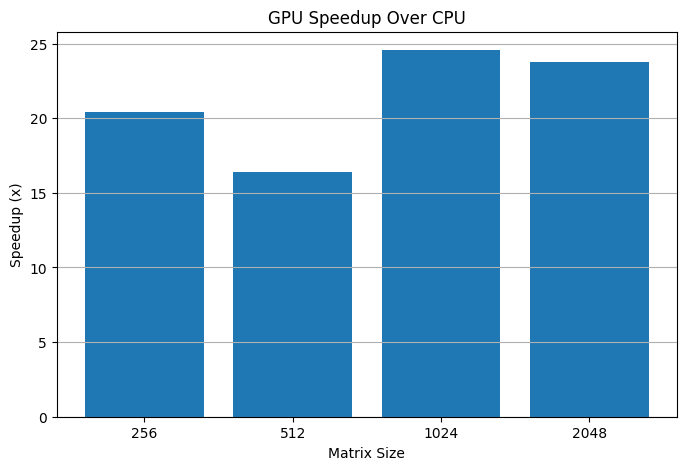

In [ ]:
speedups = [row[3] for row in results]

plt.figure(figsize=(8, 5))

plt.bar(matrix_sizes, speedups)

plt.xlabel("Matrix Size")
plt.ylabel("Speedup (x)")
plt.title("GPU Speedup Over CPU")

plt.grid(axis='y')

plt.show()

In [ ]:
!pip install numba

In [ ]:
from numba import cuda
import numpy as np

print("CUDA available:", cuda.is_available())

CUDA available: True


In [ ]:
print(cuda.get_current_device())

<CUDA device 0 'Tesla T4'>


In [ ]:
from numba import cuda
import numpy as np

@cuda.jit
def matrix_multiply(A, B, C):

    row = cuda.blockIdx.y * cuda.blockDim.y + cuda.threadIdx.y
    col = cuda.blockIdx.x * cuda.blockDim.x + cuda.threadIdx.x

    if row < C.shape[0] and col < C.shape[1]:

        total = 0.0

        for k in range(A.shape[1]):
            total += A[row, k] * B[k, col]

        C[row, col] = total

In [ ]:
import numpy as np
from numba import cuda

# Create input matrices
A = np.array([[1, 2],
              [3, 4]], dtype=np.float32)

B = np.array([[5, 6],
              [7, 8]], dtype=np.float32)

# Initialize output matrix
C = np.zeros((2, 2), dtype=np.float32)

# Copy to GPU
A_gpu = cuda.to_device(A)
B_gpu = cuda.to_device(B)
C_gpu = cuda.to_device(C)

# Configure CUDA threads
threads_per_block = (16, 16)
blocks_per_grid = (1, 1)

# Launch our custom kernel
matrix_multiply[blocks_per_grid, threads_per_block](
    A_gpu, B_gpu, C_gpu
)

# Copy result back to CPU
C = C_gpu.copy_to_host()

print("Matrix A:")
print(A)

print("Matrix B:")
print(B)

print("GPU result:")
print(C)

/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 1 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))


Matrix A:
[[1. 2.]
 [3. 4.]]
Matrix B:
[[5. 6.]
 [7. 8.]]
GPU result:
[[19. 22.]
 [43. 50.]]


In [ ]:
size = 512

A = np.random.rand(size, size).astype(np.float32)
B = np.random.rand(size, size).astype(np.float32)

C = np.zeros((size, size), dtype=np.float32)

A_gpu = cuda.to_device(A)
B_gpu = cuda.to_device(B)
C_gpu = cuda.to_device(C)

threads_per_block = (16, 16)

blocks_per_grid = (
    (size + 15) // 16,
    (size + 15) // 16
)

matrix_multiply[blocks_per_grid, threads_per_block](
    A_gpu, B_gpu, C_gpu
)

C_gpu_result = C_gpu.copy_to_host()

print("Output shape:", C_gpu_result.shape)

Output shape: (512, 512)


In [ ]:
C_numpy = np.matmul(A, B)

print("Results match:",
      np.allclose(C_gpu_result, C_numpy, rtol=1e-4, atol=1e-4))

print("Maximum absolute error:",
      np.max(np.abs(C_gpu_result - C_numpy)))

Results match: True
Maximum absolute error: 0.00010681152


In [ ]:
import torch
import time
import statistics

print("PyTorch:", torch.__version__)
print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu130
GPU: Tesla T4


In [ ]:
# CPU inputs using NumPy
A_cpu = A
B_cpu = B

# GPU inputs using PyTorch
A_torch = torch.from_numpy(A).cuda()
B_torch = torch.from_numpy(B).cuda()

# GPU inputs using Numba
A_numba = cuda.to_device(A)
B_numba = cuda.to_device(B)
C_numba = cuda.device_array((512, 512), dtype=np.float32)

# CUDA launch configuration
threads_per_block = (16, 16)
blocks_per_grid = (32, 32)

In [ ]:
cpu_times = []

for _ in range(10):
    start = time.perf_counter()

    for _ in range(20):
        C_numpy = np.matmul(A_cpu, B_cpu)

    end = time.perf_counter()
    cpu_times.append((end - start) * 1000 / 20)

cpu_time = statistics.median(cpu_times)

print("NumPy CPU time:", cpu_time, "ms")

NumPy CPU time: 5.440042525000877 ms


In [ ]:
# Warmup
for _ in range(10):
    torch.matmul(A_torch, B_torch)

torch.cuda.synchronize()

gpu_times = []

for _ in range(10):
    start = torch.cuda.Event(enable_timing=True)
    end = torch.cuda.Event(enable_timing=True)

    start.record()

    for _ in range(20):
        C_torch = torch.matmul(A_torch, B_torch)

    end.record()
    end.synchronize()

    gpu_times.append(start.elapsed_time(end) / 20)

pytorch_gpu_time = statistics.median(gpu_times)

print("PyTorch GPU time:", pytorch_gpu_time, "ms")

PyTorch GPU time: 0.13320080041885377 ms


In [ ]:
# Warmup
for _ in range(10):
    matrix_multiply[blocks_per_grid, threads_per_block](
        A_numba, B_numba, C_numba
    )

cuda.synchronize()

custom_times = []

for _ in range(10):
    start = torch.cuda.Event(enable_timing=True)
    end = torch.cuda.Event(enable_timing=True)

    start.record()

    for _ in range(20):
        matrix_multiply[blocks_per_grid, threads_per_block](
            A_numba, B_numba, C_numba
        )

    end.record()
    end.synchronize()

    custom_times.append(start.elapsed_time(end) / 20)

custom_cuda_time = statistics.median(custom_times)

print("Custom CUDA time:", custom_cuda_time, "ms")

Custom CUDA time: 2.690087985992432 ms


In [ ]:
print("\n===== PERFORMANCE COMPARISON =====")

print(f"NumPy CPU:       {cpu_time:.4f} ms")
print(f"PyTorch GPU:     {pytorch_gpu_time:.4f} ms")
print(f"Custom CUDA:     {custom_cuda_time:.4f} ms")

print("\nCustom CUDA speedup over CPU:",
      f"{cpu_time / custom_cuda_time:.2f}x")

print("PyTorch GPU speedup over CPU:",
      f"{cpu_time / pytorch_gpu_time:.2f}x")


===== PERFORMANCE COMPARISON =====
NumPy CPU:       5.4400 ms
PyTorch GPU:     0.1332 ms
Custom CUDA:     2.6901 ms

Custom CUDA speedup over CPU: 2.02x
PyTorch GPU speedup over CPU: 40.84x


In [ ]:
# Compare all implementations

print("NumPy vs PyTorch:",
      np.allclose(C_numpy, C_torch.cpu().numpy(), rtol=1e-4, atol=1e-4))

print("NumPy vs Custom CUDA:",
      np.allclose(C_numpy, C_numba.copy_to_host(), rtol=1e-4, atol=1e-4))

NumPy vs PyTorch: True
NumPy vs Custom CUDA: True


In [ ]:
@cuda.jit
def tiled_matrix_multiply(A, B, C):

    TILE_SIZE = 16

    # Shared memory
    sA = cuda.shared.array((16, 16), dtype=np.float32)
    sB = cuda.shared.array((16, 16), dtype=np.float32)

    row = cuda.blockIdx.y * TILE_SIZE + cuda.threadIdx.y
    col = cuda.blockIdx.x * TILE_SIZE + cuda.threadIdx.x

    tx = cuda.threadIdx.x
    ty = cuda.threadIdx.y

    total = 0.0

    for tile in range((A.shape[1] + TILE_SIZE - 1) // TILE_SIZE):

        # Load tiles into shared memory
        if row < A.shape[0] and tile * TILE_SIZE + tx < A.shape[1]:
            sA[ty, tx] = A[row, tile * TILE_SIZE + tx]
        else:
            sA[ty, tx] = 0.0

        if tile * TILE_SIZE + ty < B.shape[0] and col < B.shape[1]:
            sB[ty, tx] = B[tile * TILE_SIZE + ty, col]
        else:
            sB[ty, tx] = 0.0

        # Wait for all threads to finish loading
        cuda.syncthreads()

        # Multiply the tiles
        for k in range(TILE_SIZE):
            total += sA[ty, k] * sB[k, tx]

        # Wait before loading the next tiles
        cuda.syncthreads()

    if row < C.shape[0] and col < C.shape[1]:
        C[row, col] = total

In [ ]:
# Initialize output matrix
C_tiled = np.zeros((512, 512), dtype=np.float32)

# Copy output matrix to GPU
C_tiled_gpu = cuda.to_device(C_tiled)

# Configure threads and blocks
threads_per_block = (16, 16)

blocks_per_grid = (
    (512 + 15) // 16,
    (512 + 15) // 16
)

# Launch tiled CUDA kernel
tiled_matrix_multiply[blocks_per_grid, threads_per_block](
    A_numba, B_numba, C_tiled_gpu
)

# Copy result back to CPU
C_tiled_result = C_tiled_gpu.copy_to_host()

print("Output shape:", C_tiled_result.shape)

Output shape: (512, 512)


In [ ]:
# Warmup
for _ in range(10):
    tiled_matrix_multiply[blocks_per_grid, threads_per_block](
        A_numba, B_numba, C_tiled_gpu
    )

cuda.synchronize()

tiled_times = []

for _ in range(10):
    start = torch.cuda.Event(enable_timing=True)
    end = torch.cuda.Event(enable_timing=True)

    start.record()

    for _ in range(20):
        tiled_matrix_multiply[blocks_per_grid, threads_per_block](
            A_numba, B_numba, C_tiled_gpu
        )

    end.record()
    end.synchronize()

    tiled_times.append(start.elapsed_time(end) / 20)

tiled_cuda_time = statistics.median(tiled_times)

print("Tiled CUDA:", tiled_cuda_time, "ms")

Tiled CUDA: 2.45241756439209 ms


In [ ]:
print("\n===== GPU PERFORMANCE COMPARISON =====")

print(f"Basic CUDA:  {custom_cuda_time:.4f} ms")
print(f"Tiled CUDA:  {tiled_cuda_time:.4f} ms")
print(f"PyTorch GPU: {pytorch_gpu_time:.4f} ms")

print("\nTiled kernel speedup over basic:",
      f"{custom_cuda_time / tiled_cuda_time:.2f}x")

print("PyTorch speedup over tiled:",
      f"{tiled_cuda_time / pytorch_gpu_time:.2f}x")


===== GPU PERFORMANCE COMPARISON =====
Basic CUDA:  2.6901 ms
Tiled CUDA:  2.4524 ms
PyTorch GPU: 0.1332 ms

Tiled kernel speedup over basic: 1.10x
PyTorch speedup over tiled: 18.41x


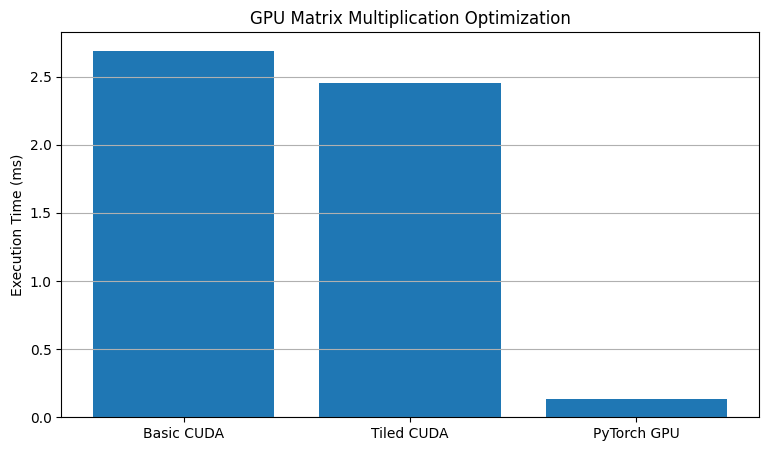

In [ ]:
import matplotlib.pyplot as plt

labels = ["Basic CUDA", "Tiled CUDA", "PyTorch GPU"]
times = [custom_cuda_time, tiled_cuda_time, pytorch_gpu_time]

plt.figure(figsize=(9, 5))
plt.bar(labels, times)
plt.ylabel("Execution Time (ms)")
plt.title("GPU Matrix Multiplication Optimization")
plt.grid(axis="y")
plt.show()

In [ ]:
@cuda.jit
def register_tiled_matmul(A, B, C):

    TILE = 16

    sA = cuda.shared.array((32, 16), dtype=np.float32)
    sB = cuda.shared.array((16, 32), dtype=np.float32)

    tx = cuda.threadIdx.x
    ty = cuda.threadIdx.y

    row = cuda.blockIdx.y * 32 + ty
    col = cuda.blockIdx.x * 32 + tx

    acc00 = 0.0
    acc01 = 0.0
    acc10 = 0.0
    acc11 = 0.0

    for tile in range((A.shape[1] + 15) // 16):

        # Load A tiles
        if row < A.shape[0] and tile * 16 + tx < A.shape[1]:
            sA[ty, tx] = A[row, tile * 16 + tx]
        else:
            sA[ty, tx] = 0.0

        if row + 16 < A.shape[0] and tile * 16 + tx < A.shape[1]:
            sA[ty + 16, tx] = A[row + 16, tile * 16 + tx]
        else:
            sA[ty + 16, tx] = 0.0

        # Load B tiles
        if tile * 16 + ty < B.shape[0] and col < B.shape[1]:
            sB[ty, tx] = B[tile * 16 + ty, col]
        else:
            sB[ty, tx] = 0.0

        if tile * 16 + ty < B.shape[0] and col + 16 < B.shape[1]:
            sB[ty, tx + 16] = B[tile * 16 + ty, col + 16]
        else:
            sB[ty, tx + 16] = 0.0

        cuda.syncthreads()

        for k in range(16):
            a0 = sA[ty, k]
            a1 = sA[ty + 16, k]

            b0 = sB[k, tx]
            b1 = sB[k, tx + 16]

            acc00 += a0 * b0
            acc01 += a0 * b1
            acc10 += a1 * b0
            acc11 += a1 * b1

        cuda.syncthreads()

    if row < C.shape[0] and col < C.shape[1]:
        C[row, col] = acc00

    if row < C.shape[0] and col + 16 < C.shape[1]:
        C[row, col + 16] = acc01

    if row + 16 < C.shape[0] and col < C.shape[1]:
        C[row + 16, col] = acc10

    if row + 16 < C.shape[0] and col + 16 < C.shape[1]:
        C[row + 16, col + 16] = acc11

In [ ]:
C_register_gpu = cuda.device_array((512, 512), dtype=np.float32)

threads = (16, 16)
blocks = (16, 16)

register_tiled_matmul[blocks, threads](
    A_numba, B_numba, C_register_gpu
)

C_register = C_register_gpu.copy_to_host()

print("Correctness:",
      np.allclose(C_register, C_numpy, rtol=1e-4, atol=1e-4))

Correctness: True


In [43]:
import statistics
import torch

# Warm-up
for _ in range(10):
    register_tiled_matmul[blocks, threads](
        A_numba, B_numba, C_register_gpu
    )

cuda.synchronize()

# Benchmark
register_times = []

for _ in range(10):
    start = torch.cuda.Event(enable_timing=True)
    end = torch.cuda.Event(enable_timing=True)

    start.record()

    for _ in range(20):
        register_tiled_matmul[blocks, threads](
            A_numba, B_numba, C_register_gpu
        )

    end.record()
    end.synchronize()

    register_times.append(start.elapsed_time(end) / 20)

register_cuda_time = statistics.median(register_times)

print("Register-tiled CUDA:", round(register_cuda_time, 4), "ms")

Register-tiled CUDA: 2.6392 ms


In [44]:
print("Basic CUDA:", round(custom_cuda_time, 4), "ms")
print("Shared-memory tiled:", round(tiled_cuda_time, 4), "ms")
print("Register-tiled:", round(register_cuda_time, 4), "ms")
print("PyTorch GPU:", round(pytorch_gpu_time, 4), "ms")

Basic CUDA: 2.6901 ms
Shared-memory tiled: 2.4524 ms
Register-tiled: 2.6392 ms
PyTorch GPU: 0.1332 ms


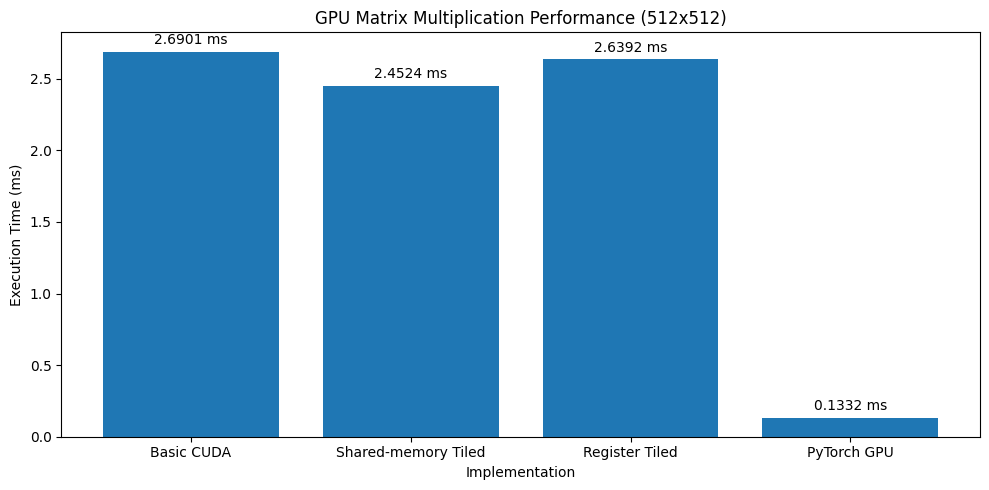

In [45]:
import matplotlib.pyplot as plt

implementations = [
    "Basic CUDA",
    "Shared-memory Tiled",
    "Register Tiled",
    "PyTorch GPU"
]

times = [
    custom_cuda_time,
    tiled_cuda_time,
    register_cuda_time,
    pytorch_gpu_time
]

plt.figure(figsize=(10, 5))

bars = plt.bar(implementations, times)

plt.title("GPU Matrix Multiplication Performance (512x512)")
plt.xlabel("Implementation")
plt.ylabel("Execution Time (ms)")

plt.bar_label(bars, fmt="%.4f ms", padding=3)

plt.tight_layout()
plt.show()